## 0. Ensure compatible dependencies

The repository does not define a shared Python environment, so this first cell asks `pip` to verify the declared version ranges in Google Colab and GitLab runners. Packages that already satisfy the requirements are preserved; missing or incompatible packages are installed or updated. `pyarrow` is required because Pandas needs a Parquet engine to read the treated dataset.

In [1]:
import subprocess
import sys

required_packages = {
    "numpy": "numpy>=1.26,<3",
    "pandas": "pandas>=2.2,<4",
    "pyarrow": "pyarrow>=18",
    "matplotlib": "matplotlib>=3.8,<4",
}
print("Checking required package versions...")
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--quiet",
    "--only-binary=:all:",
    *required_packages.values(),
])
print("Required package versions are satisfied.")

Checking required package versions...


Required package versions are satisfied.


# Relationships among Breast Cancer Care Variables in Brazil's North Region

## Objective

This notebook explores relationships among variables in the treated 2025 North-region breast cancer dataset. The analysis focuses on the variables selected by the project group: `VL_TOTAL_REMUNERACAO` (total remuneration), `QT_ITEM_EVENTO_INFORMADO` (reported item quantity), and the monthly mean of `QT_ITEM_EVENTO_INFORMADO`.

The four charts are relational rather than single-variable distributions. Together, they examine temporal behavior, the association between procedure quantity and remuneration, geographic differences, and the relationship between demographic/geographic features and a high-specificity technology proxy. All charts are produced exclusively with Matplotlib.

## 1. Environment and reproducible data loading

**Upstream:** `04_data_treatment.ipynb`. **Required input:** `data/processed/north_region_mama_2025_data_en.parquet`. **Output:** in-notebook charts only; no pipeline artifact is generated. **Downstream:** none. Notebooks 05 and 07 independently read the same canonical output from notebook 04.

The path resolver supports execution from the repository root or from `notebooks/`.

In [2]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

print(
    f"Python {sys.version.split()[0]} | NumPy {np.__version__} | "
    f"Pandas {pd.__version__} | Matplotlib {matplotlib.__version__}"
)

plt.style.use("default")
plt.rcParams.update({
    "figure.figsize": (11, 6),
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "font.size": 10,
})

WORKING_DIR = Path.cwd().resolve()
REPO_ROOT = WORKING_DIR.parent if WORKING_DIR.name == "notebooks" else WORKING_DIR
ASSETS_DIR = REPO_ROOT / "assets"
data_path = REPO_ROOT / "data" / "processed" / "north_region_mama_2025_data_en.parquet"

if not data_path.is_file():
    raise FileNotFoundError(
        "Missing treated dataset. Run 04_data_treatment.ipynb first. "
        f"Expected path: {data_path}"
    )

required_columns = [
    "MES",
    "UF_PRESTADOR",
    "QT_ITEM_EVENTO_INFORMADO",
    "VL_TOTAL_REMUNERACAO",
    "FAIXA_ETARIA",
    "IND_HIGH_SPECIFICITY_PROXY",
]
df = pd.read_parquet(data_path, columns=required_columns)
print(f"Loaded {len(df):,} rows from {data_path}")

Python 3.14.2 | NumPy 2.5.2 | Pandas 3.0.5 | Matplotlib 3.11.1


Loaded 310,340 rows from data\processed\north_region_mama_2025_data_en.parquet


## 2. Data-quality checks and preparation

Before aggregation, the notebook verifies the expected schema, converts the month field explicitly, and reports missing values. Missing measurements are not replaced with zero: zero would mean an observed quantity or remuneration, while a missing value means the measurement was unavailable. Pandas therefore excludes missing observations only from the calculation that needs the affected variable. State-level completeness is also reported because missingness in `QT_ITEM_EVENTO_INFORMADO` is highly uneven: Amazonas has 15.93% missing values, compared with 0.98% in Pará. This matters because Amazonas also has the highest tail-driven mean quantity.

In [3]:
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise KeyError(f"Required columns are missing: {missing_columns}")

df = df.copy()
df["MES"] = pd.to_datetime(df["MES"], errors="coerce")

quality_summary = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (100 * df.isna().mean()).round(2),
})
display(quality_summary)

state_quantity_quality = (
    df.groupby("UF_PRESTADOR", observed=True)
      .agg(
          total_rows=("QT_ITEM_EVENTO_INFORMADO", "size"),
          valid_quantity_observations=("QT_ITEM_EVENTO_INFORMADO", "count"),
      )
)
state_quantity_quality["missing_quantity_percent"] = (
    100 * (1 - state_quantity_quality["valid_quantity_observations"]
           / state_quantity_quality["total_rows"])
).round(2)
display(state_quantity_quality)

print(
    f"Period: {df['MES'].min():%B %Y} to {df['MES'].max():%B %Y} | "
    f"Months: {df['MES'].nunique()} | States: {df['UF_PRESTADOR'].nunique()}"
)

,data_type,missing_count,missing_percent
MES,datetime64[us],0,0.00
UF_PRESTADOR,category,0,0.00
QT_ITEM_EVENTO_INFORMADO,float64,14777,4.76
VL_TOTAL_REMUNERACAO,float64,19703,6.35
FAIXA_ETARIA,str,0,0.00
IND_HIGH_SPECIFICITY_PROXY,int64,0,0.00


,total_rows,valid_quantity_observations,missing_quantity_percent
UF_PRESTADOR,,,
AC,5691,5689,0.04
AM,78613,66088,15.93
AP,14351,14253,0.68
PA,155153,153637,0.98
RO,28687,28097,2.06
RR,5318,5297,0.39
TO,22527,22502,0.11


Period: January 2025 to December 2025 | Months: 12 | States: 7


## 3. Chart 1 — Monthly mean of reported item quantity

**Variables selected:** `MES` and `QT_ITEM_EVENTO_INFORMADO`.

**Why this pairing:** Time may carry trend or seasonal information that is useful to a predictive model. Plotting the mean reported quantity by month directly implements the group's selected monthly metric and shows whether the intensity of the high-quantity tail changes across 2025. Because the median is 1 in every month, the mean must not be read as the typical record. The number of valid observations is added as a second visual encoding through bar height, so the tail-driven monthly mean can be interpreted together with its sample size.

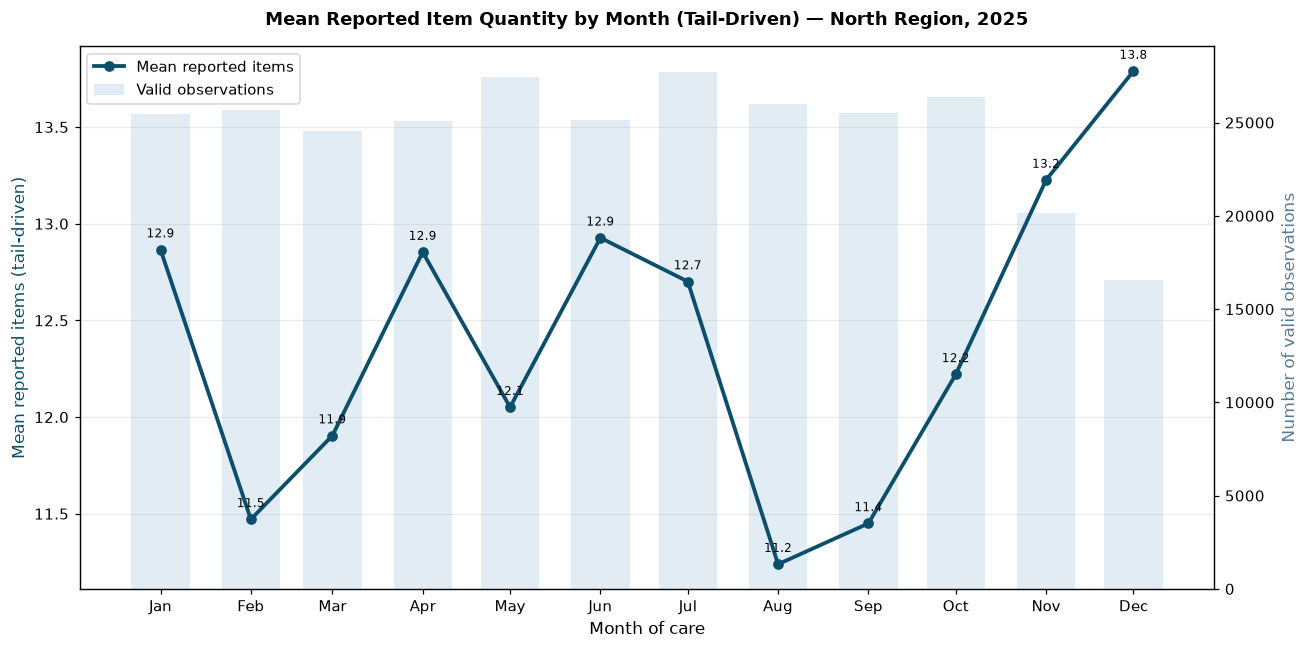

In [4]:
monthly = (
    df.dropna(subset=["MES", "QT_ITEM_EVENTO_INFORMADO"])
      .groupby("MES", as_index=False)
      .agg(
          mean_reported_items=("QT_ITEM_EVENTO_INFORMADO", "mean"),
          valid_observations=("QT_ITEM_EVENTO_INFORMADO", "size"),
      )
      .sort_values("MES")
)

fig, ax_mean = plt.subplots(figsize=(12, 6))
ax_count = ax_mean.twinx()
ax_mean.set_zorder(ax_count.get_zorder() + 1)
ax_mean.patch.set_visible(False)

ax_count.bar(
    monthly["MES"], monthly["valid_observations"],
    width=20, color="#BFD7EA", alpha=0.45, label="Valid observations"
)
ax_mean.plot(
    monthly["MES"], monthly["mean_reported_items"],
    color="#0B4F6C", linewidth=2.5, marker="o", markersize=6,
    label="Mean reported items"
)

for month, mean_value in zip(monthly["MES"], monthly["mean_reported_items"]):
    ax_mean.annotate(
        f"{mean_value:.1f}", (month, mean_value),
        xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8
    )

ax_mean.set_title("Mean Reported Item Quantity by Month (Tail-Driven) — North Region, 2025", pad=14)
ax_mean.set_xlabel("Month of care")
ax_mean.set_ylabel("Mean reported items (tail-driven)", color="#0B4F6C")
ax_count.set_ylabel("Number of valid observations", color="#547A95")
ax_mean.xaxis.set_major_locator(mdates.MonthLocator())
ax_mean.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax_mean.grid(axis="y", alpha=0.25)
ax_count.grid(False)
handles_1, labels_1 = ax_mean.get_legend_handles_labels()
handles_2, labels_2 = ax_count.get_legend_handles_labels()
ax_mean.legend(handles_1 + handles_2, labels_1 + labels_2, loc="upper left")
fig.tight_layout()
fig.savefig(ASSETS_DIR / "reported-item-by-month.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation.** The monthly mean is relatively stable but not constant. It ranges from **11.2 items in August** to **13.8 items in December**. December is approximately 22.7% above August, while the median remains 1 item in every month (checked below), indicating that the mean is influenced by a smaller number of high-quantity events. The valid sample also falls from 27,698 observations in July to 16,551 in December. The project documentation notes that claims may have a structural reporting delay of roughly three to six months, so lower late-year counts may reflect incomplete data maturity rather than lower underlying demand. Month may be a useful feature, but the late-year increase must be tested against reporting lag, sample composition, and extreme values instead of being interpreted as broad growth in typical procedure volume.

In [5]:
monthly_medians = df.groupby("MES")["QT_ITEM_EVENTO_INFORMADO"].median()
assert monthly_medians.eq(1).all(), "Monthly medians differ from the documented result."
monthly.round({"mean_reported_items": 2})

,MES,mean_reported_items,valid_observations
0,2025-01-01,12.87,25450
1,2025-02-01,11.47,25648
2,2025-03-01,11.90,24567
3,2025-04-01,12.85,25101
4,2025-05-01,12.05,27454
5,2025-06-01,12.93,25118
6,2025-07-01,12.70,27698
7,2025-08-01,11.24,25986
8,2025-09-01,11.45,25493
9,2025-10-01,12.22,26361


## 4. Chart 2 — Reported quantity versus total remuneration

**Variables selected:** `QT_ITEM_EVENTO_INFORMADO` and `VL_TOTAL_REMUNERACAO`.

**Why this pairing:** This chart tests whether events with more reported items also tend to have greater total remuneration. That association is directly relevant if remuneration or quantity will be predicted. A conventional scatter plot would hide the dense concentration of overlapping records, so a Matplotlib hexagonal-density plot is used. Both axes are logarithmic because the positive values span several orders of magnitude; this makes the central pattern visible without deleting valid high-value observations. Records missing either variable, and zero remuneration values that cannot be displayed on a log axis, are excluded only from this chart.

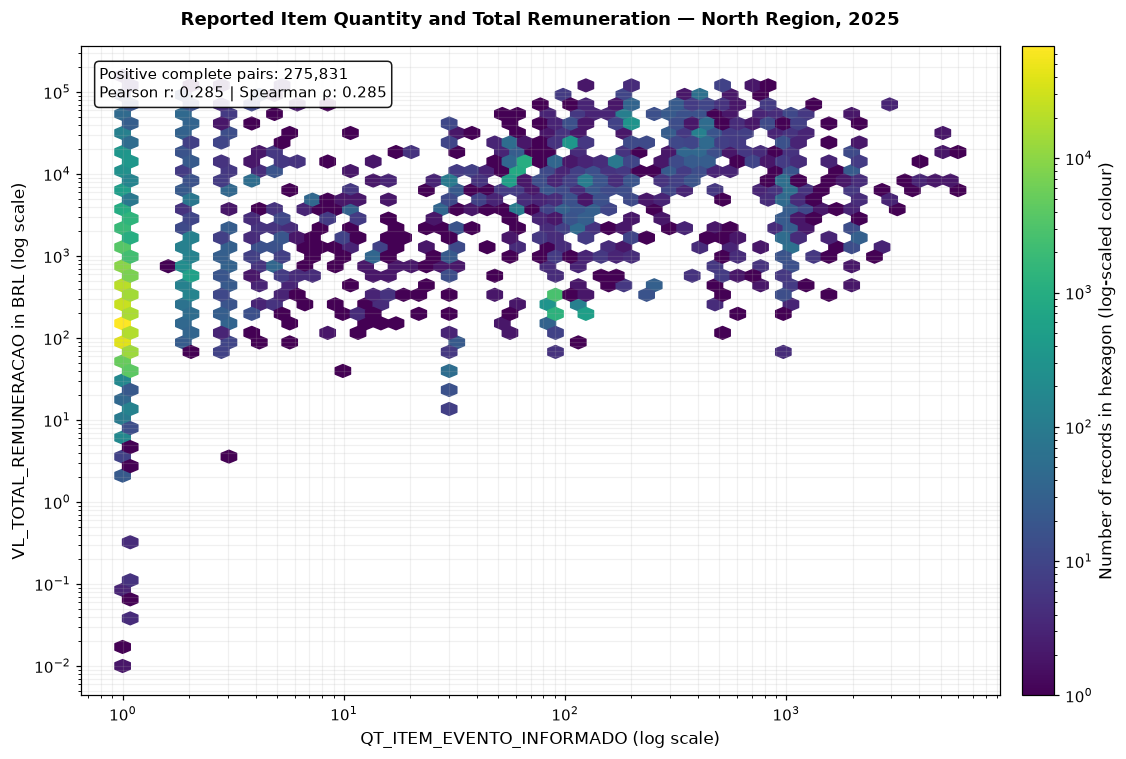

In [6]:
quantity_remuneration = df[[
    "QT_ITEM_EVENTO_INFORMADO", "VL_TOTAL_REMUNERACAO"
]].dropna()
positive_pairs = quantity_remuneration[
    (quantity_remuneration["QT_ITEM_EVENTO_INFORMADO"] > 0)
    & (quantity_remuneration["VL_TOTAL_REMUNERACAO"] > 0)
]

pearson_r = positive_pairs.corr(method="pearson").iloc[0, 1]
spearman_r = positive_pairs.corr(method="spearman").iloc[0, 1]

fig, ax = plt.subplots(figsize=(11, 7))
density = ax.hexbin(
    positive_pairs["QT_ITEM_EVENTO_INFORMADO"],
    positive_pairs["VL_TOTAL_REMUNERACAO"],
    gridsize=55, xscale="log", yscale="log", bins="log",
    mincnt=1, cmap="viridis"
)
colorbar = fig.colorbar(density, ax=ax, pad=0.02)
colorbar.set_label("Number of records in hexagon (log-scaled colour)")

ax.set_title("Reported Item Quantity and Total Remuneration — North Region, 2025", pad=14)
ax.set_xlabel("QT_ITEM_EVENTO_INFORMADO (log scale)")
ax.set_ylabel("VL_TOTAL_REMUNERACAO in BRL (log scale)")
ax.grid(True, which="both", alpha=0.18)
ax.text(
    0.02, 0.97,
    f"Positive complete pairs: {len(positive_pairs):,}\n"
    f"Pearson r: {pearson_r:.3f} | Spearman ρ: {spearman_r:.3f}",
    transform=ax.transAxes, va="top",
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.9}
)
fig.tight_layout()
fig.savefig(ASSETS_DIR / "reported-item-quantity-and-remuneration.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation.** Reported quantity and total remuneration have a **positive but modest association**: Pearson's correlation is approximately **0.285**, and Spearman's rank correlation is approximately **0.285**. Higher item quantities therefore tend to accompany higher remuneration, but quantity alone does not explain most of the financial variation. The broad vertical spread at common quantities—especially at one item—suggests that procedure type, treatment characteristics, provider, and geography may add important predictive information. The near-identical Pearson and Spearman results also indicate that the conclusion is not solely an artifact of the raw scale.

## 5. Chart 3 — State-level relationship between mean quantity and mean remuneration

**Variables selected:** `UF_PRESTADOR`, `QT_ITEM_EVENTO_INFORMADO`, and `VL_TOTAL_REMUNERACAO`; record count is derived from the same grouped data.

**Why this pairing:** A predictive model trained across the entire North region may need to account for geographic differences. Each point represents one provider state: horizontal position is the tail-driven mean reported quantity, vertical position is mean total remuneration, and point area represents the number of non-null quantity observations that actually contribute to the horizontal mean. This simultaneously compares high-quantity tail intensity, financial level, and sample representation. Means are retained because they correspond to the group's requested aggregation, but the median is 1 in every state; therefore, the horizontal differences describe a small high-quantity minority rather than the typical record.

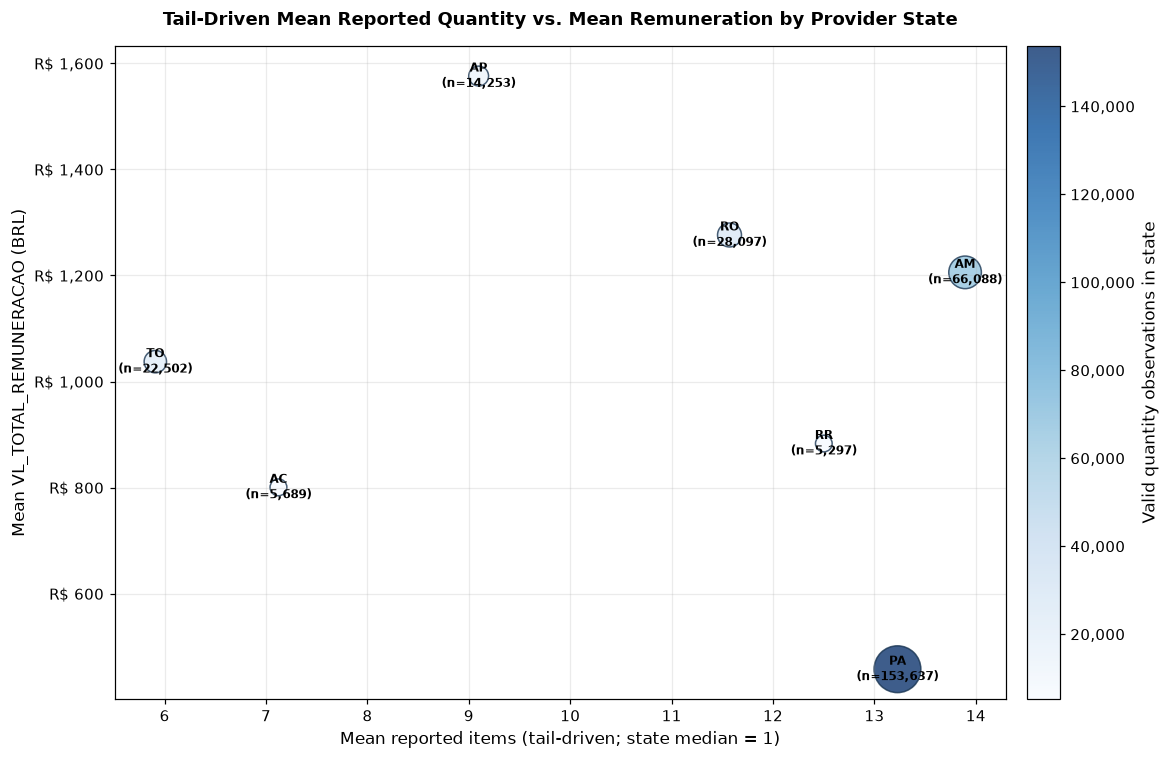

In [7]:
state_summary = (
    df.groupby("UF_PRESTADOR", observed=True)
      .agg(
          mean_reported_items=("QT_ITEM_EVENTO_INFORMADO", "mean"),
          median_reported_items=("QT_ITEM_EVENTO_INFORMADO", "median"),
          mean_total_remuneration=("VL_TOTAL_REMUNERACAO", "mean"),
          record_count=("QT_ITEM_EVENTO_INFORMADO", "count"),
      )
      .dropna()
      .reset_index()
)

bubble_sizes = 90 + 850 * (state_summary["record_count"] / state_summary["record_count"].max())

fig, ax = plt.subplots(figsize=(11, 7))
scatter = ax.scatter(
    state_summary["mean_reported_items"],
    state_summary["mean_total_remuneration"],
    s=bubble_sizes, c=state_summary["record_count"],
    cmap="Blues", alpha=0.78, edgecolor="#16324F", linewidth=1
)

for row in state_summary.itertuples(index=False):
    ax.annotate(
        f"{row.UF_PRESTADOR}\n(n={row.record_count:,})",
        (row.mean_reported_items, row.mean_total_remuneration),
        ha="center", va="center", fontsize=8, fontweight="bold"
    )

colorbar = fig.colorbar(scatter, ax=ax, pad=0.02)
colorbar.set_label("Valid quantity observations in state")
colorbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:,.0f}"))
ax.set_title("Tail-Driven Mean Reported Quantity vs. Mean Remuneration by Provider State", pad=14)
ax.set_xlabel("Mean reported items (tail-driven; state median = 1)")
ax.set_ylabel("Mean VL_TOTAL_REMUNERACAO (BRL)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"R$ {value:,.0f}"))
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(ASSETS_DIR / "reported-quantity-vs-remuneration.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation.** The median reported quantity is **1 item in every state**, and 93.27% of all valid quantity values equal 1. The apparent state spread in the mean—from about **5.9 to 13.9 items**—is therefore almost entirely driven by a small high-quantity minority, not by substantial differences in the typical record. Pará is the clearest example: its mean is about **13.2**, although its 95th percentile is still 1. Amazonas has the highest tail-driven mean (about **13.9 items**) but also has only 66,088 valid quantity observations out of 78,613 rows, or **15.93% missing**, versus **0.98% in Pará**. Amapá has the highest mean remuneration (about **R$1,576**), while Pará has the lowest (about **R$457**). These tail, remuneration, completeness, and sample-size differences justify state-stratified diagnostics, but the mean quantity must not be presented as typical reporting volume.

In [8]:
state_table = state_summary.sort_values("mean_total_remuneration", ascending=False).copy()
state_table["mean_reported_items"] = state_table["mean_reported_items"].round(2)
state_table["median_reported_items"] = state_table["median_reported_items"].round(2)
state_table["mean_total_remuneration"] = state_table["mean_total_remuneration"].round(2)
display(state_table)

,UF_PRESTADOR,mean_reported_items,median_reported_items,mean_total_remuneration,record_count
2,AP,9.10,1.0,1576.02,14253
4,RO,11.57,1.0,1276.30,28097
1,AM,13.89,1.0,1205.84,66088
6,TO,5.91,1.0,1037.42,22502
5,RR,12.50,1.0,883.06,5297
0,AC,7.12,1.0,800.44,5689
3,PA,13.23,1.0,457.48,153637


## 6. Chart 4 — High-specificity proxy rate by state and age group

**Variables selected:** `UF_PRESTADOR`, `FAIXA_ETARIA`, and `IND_HIGH_SPECIFICITY_PROXY`.

**Why this relationship is especially relevant to the project:** The TAPI defines the core modeling problem as estimating service potential from demographic profile, geographic location, and the use of health technologies. `IND_HIGH_SPECIFICITY_PROXY` is the treated dataset's closest available indicator of a record strongly associated with the breast-cancer scope. The heatmap therefore examines whether this model-relevant proxy changes jointly across state and age group. Rates are used instead of raw counts so that large states do not automatically appear to have stronger proxy concentration merely because they contribute more records. Only adult age groups from 20 years onward are shown because they are the analytically relevant bands for this breast-cancer exploration. Each cell also reports its denominator to prevent a high percentage from being interpreted without considering sample size.

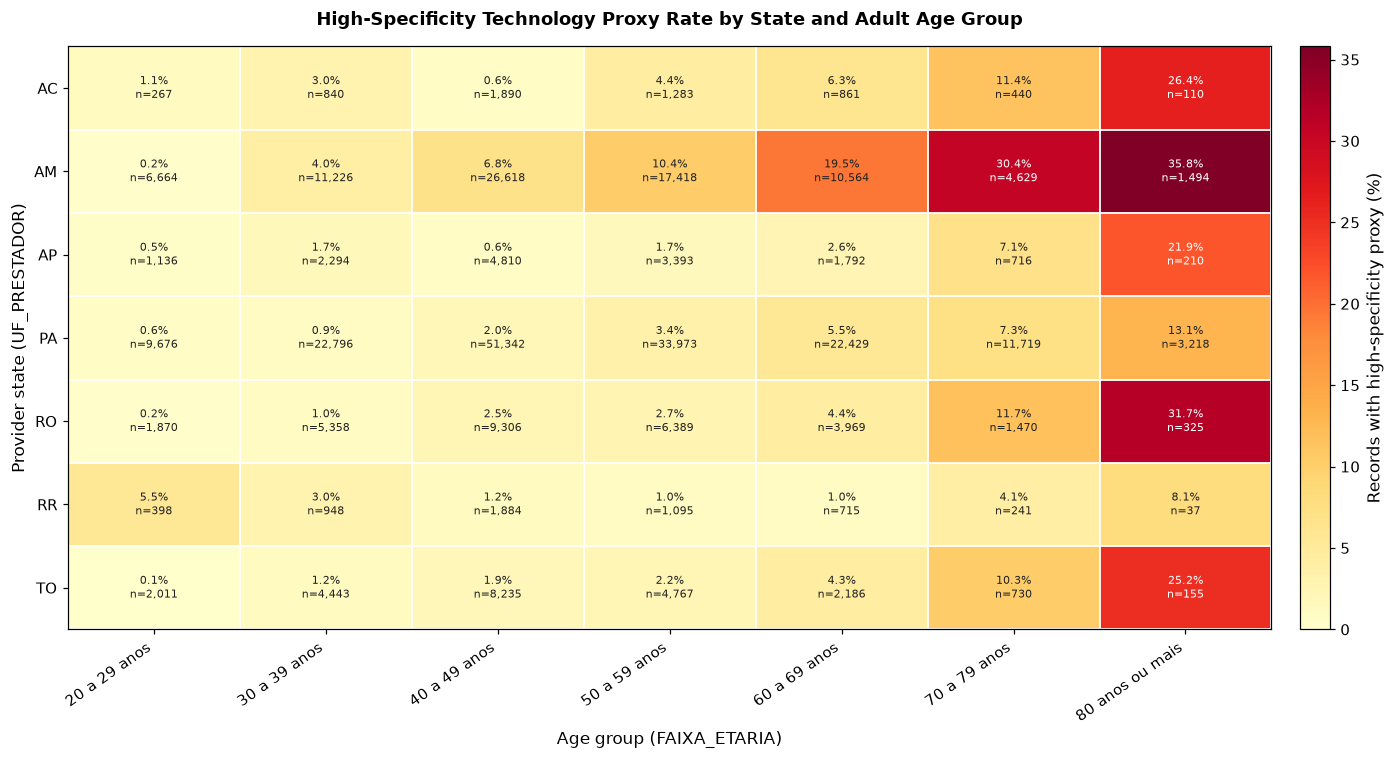

In [9]:
adult_age_order = [
    "20 a 29 anos", "30 a 39 anos", "40 a 49 anos",
    "50 a 59 anos", "60 a 69 anos", "70 a 79 anos",
    "80 anos ou mais",
]
state_order = sorted(df["UF_PRESTADOR"].astype(str).unique())
adult_proxy = df[df["FAIXA_ETARIA"].isin(adult_age_order)].copy()

proxy_rate = (
    adult_proxy.groupby(["UF_PRESTADOR", "FAIXA_ETARIA"], observed=True)
               ["IND_HIGH_SPECIFICITY_PROXY"].mean()
               .mul(100).unstack()
               .reindex(index=state_order, columns=adult_age_order)
)
proxy_n = (
    adult_proxy.groupby(["UF_PRESTADOR", "FAIXA_ETARIA"], observed=True)
               .size().unstack()
               .reindex(index=state_order, columns=adult_age_order)
)

fig, ax = plt.subplots(figsize=(14, 7))
heatmap_values = np.ma.masked_invalid(proxy_rate.to_numpy(dtype=float))
image = ax.imshow(heatmap_values, cmap="YlOrRd", aspect="auto", vmin=0)
colorbar = fig.colorbar(image, ax=ax, pad=0.02)
colorbar.set_label("Records with high-specificity proxy (%)")

ax.set_xticks(np.arange(len(adult_age_order)), labels=adult_age_order, rotation=35, ha="right")
ax.set_yticks(np.arange(len(state_order)), labels=state_order)
ax.set_xlabel("Age group (FAIXA_ETARIA)")
ax.set_ylabel("Provider state (UF_PRESTADOR)")
ax.set_title("High-Specificity Technology Proxy Rate by State and Adult Age Group", pad=14)

threshold = np.nanmax(proxy_rate.to_numpy()) * 0.55
for row_index, state in enumerate(state_order):
    for column_index, age_group in enumerate(adult_age_order):
        rate = proxy_rate.loc[state, age_group]
        sample_size = proxy_n.loc[state, age_group]
        if pd.notna(rate) and pd.notna(sample_size):
            text_color = "white" if rate > threshold else "#222222"
            ax.text(
                column_index, row_index, f"{rate:.1f}%\nn={sample_size:,.0f}",
                ha="center", va="center", fontsize=7.5, color=text_color
            )

ax.set_xticks(np.arange(-0.5, len(adult_age_order), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(state_order), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1.2)
ax.tick_params(which="minor", bottom=False, left=False)
fig.tight_layout()
fig.savefig(ASSETS_DIR / "output-state-and-age.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation.** The high-specificity proxy rate increases markedly with age across the region: from about **0.5% among records aged 20–29** to **21.2% among records aged 80 or older**. Geography modifies that pattern in well-populated cells. For example, among records aged 70–79, the rate is approximately **30.4% in Amazonas** (`n=4,629`) and **7.3% in Pará** (`n=11,719`); among records aged 80 or older, Amazonas reaches **35.8%** (`n=1,494`) and Pará **13.1%** (`n=3,218`). Roraima's displayed 70–79 rate is **4.1%**, while its 80+ estimate is based on only 37 records and should be treated as indicative rather than as strong evidence of a geographic effect. These results make age group and provider state plausible predictive features and suggest testing their interaction rather than assuming one common age effect for all states. However, the chart measures the share of claim records flagged by an engineered proxy—not confirmed diagnoses, treatment eligibility, or unique patients. It must therefore guide feature engineering and validation against clinical definitions, not be reported as breast-cancer prevalence. One final note on units: these rates are shares of billed **records**. Notebook 07 tests the same age-by-state relationship per **healthcare event**, flagging an event when any of its item rows carries the proxy, which places the 80+ rate at 23.2% rather than the 21.2% shown here. The two figures count different units and are consistent with each other; neither supersedes the other.

## 7. Implications for future predictive modeling

The four relationships support the following hypotheses for the modeling stage:

1. **Time should be tested, not assumed to be neutral.** Monthly tail-driven means vary across 2025, but the median is 1 in every month. The mean pattern therefore reflects a small high-quantity minority and may also be affected by case mix, reporting delay, and changing sample sizes.
2. **Quantity is informative but insufficient for remuneration prediction.** Its positive correlation with total remuneration is modest, so additional clinical, procedural, and reimbursement variables are likely necessary.
3. **Geography, tail behavior, completeness, and sample imbalance matter.** State medians are all 1, so differences in mean quantity are tail-driven. Pará and Amazonas dominate the observations, while Amazonas has unusually high quantity missingness. State-aware validation, completeness checks, grouped error metrics, and geographic features should be considered.
4. **Chart 4 — demographic and geographic effects should be modeled jointly.** The high-specificity proxy rate rises with age but differs substantially by state, supporting interaction terms or tree-based models that can learn non-additive effects.
5. **Transformation comparisons belong primarily to the regression arm.** Both selected numeric variables are strongly right-skewed, so raw, capped, and log-normalized representations should be compared for regression models, where scale and functional form matter. For tree-based models, these monotonic, rank-equivalent quantity representations are not meaningfully different splitting experiments; robust handling should focus instead on tail ties, missingness, and validation stability.

### Specific modeling implication from Chart 4

Chart 4 indicates a probable interaction between `FAIXA_ETARIA` and `UF_PRESTADOR`: the relationship between age and the high-specificity proxy is not uniform across states. The modeling stage should therefore compare (a) a regression containing an explicit `FAIXA_ETARIA × UF_PRESTADOR` interaction with (b) non-linear tree-based models such as Decision Tree or Random Forest, which can learn this interaction automatically. Performance should also be reported by state and age group because the segment sizes are highly imbalanced. Before `IND_HIGH_SPECIFICITY_PROXY` is used as a target or eligibility signal, its rule must be validated against the clinical definitions adopted by the project and, ideally, with the partner team.

These are exploratory associations, not causal conclusions. The charts guide feature engineering and hypothesis testing; they do not establish that month, quantity, state, or age causes a clinical or financial outcome. The proxy represents administrative records, not confirmed diagnoses or unique patients.

## Reproducibility note

The notebook requires Python, Pandas, Matplotlib, NumPy, and PyArrow. The first code cell asks `pip` to enforce the declared compatible version ranges, rather than checking only whether a package name is importable. Package installation or upgrading requires network access when the environment does not already satisfy those ranges; the analysis itself makes no external data or network request.

## References

1. Agência Nacional de Saúde Suplementar (ANS). Dados abertos: TISS Ambulatorial [Internet]. Brasília: ANS; 2026 [cited 2026 Sep 11]. Available from: https://dadosabertos.ans.gov.br/FTP/PDA/TISS/AMBULATORIAL/
2. Sociedade Brasileira de Oncologia Clínica (SBOC). Diretrizes SBOC 2025: câncer de mama — estadiamento, neoadjuvante, adjuvante e doença avançada. São Paulo: SBOC; 2025.
3. Hunter JD. Matplotlib: a 2D graphics environment. Comput Sci Eng. 2007;9(3):90-5.
4. Instituto Nacional de Câncer (INCA). Estimativa 2026: incidência de câncer no Brasil [Internet]. Rio de Janeiro: INCA; 2026 [cited 2026 Sep 11]. Available from: https://www.gov.br/inca/pt-br/assuntos/cancer/numeros/estimativa/introducao
